# Лабораторная работа № 2
## K-means


## Импорт библиотек


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.neighbors import NearestNeighbors
from scipy.cluster.hierarchy import linkage, cut_tree


## Подготовка данных


In [ ]:
# Удаляем неполные наблюдения и стандартизируем признаки перед расчётом расстояний.
DATA_URL = "https://raw.githubusercontent.com/IvanManomenov/python_data_analytics/main/lab2/Econom_Cities_data.csv"
raw2 = pd.read_csv(DATA_URL, sep=';', decimal=',', na_values=[-9999])
features2 = ['Work', 'Price', 'Salary']
cities2 = raw2.dropna(subset=features2).copy().reset_index(drop=True)
scaler2 = StandardScaler()
X2 = scaler2.fit_transform(cities2[features2])
display(raw2[features2].isna().sum().to_frame('Пропуски'))
print('В анализе:', len(cities2), 'городов')


,Пропуски
Work,2
Price,0
Salary,2


В анализе: 46 городов


## Кластеризация


In [ ]:
# K-means минимизирует сумму квадратов расстояний до центров групп.
# Для каждого k используем 50 инициализаций и фиксируем random_state для воспроизводимости.
km_models, km_rows = {}, []
for k in range(2, 9):
    model = KMeans(n_clusters=k, n_init=50, random_state=42).fit(X2)
    km_models[k] = model
    km_rows.append({'k': k, 'inertia': model.inertia_,
                    'silhouette': silhouette_score(X2, model.labels_),
                    'sizes': str(np.bincount(model.labels_).tolist())})
km_scores = pd.DataFrame(km_rows)
display(km_scores.round(4))
# Выбираем k по силуэту; инерция всегда убывает с ростом k и сама по себе не задаёт оптимум.
km_k = int(km_scores.sort_values(['silhouette', 'k'], ascending=[False, True]).iloc[0]['k'])
km_model = km_models[km_k]
# Упорядочиваем номера групп по среднему индексу зарплаты (по убыванию).
order2 = np.argsort(scaler2.inverse_transform(km_model.cluster_centers_)[:, 2])[::-1]
map2 = {int(old): new+1 for new, old in enumerate(order2)}
km_labels = np.array([map2[int(c)] for c in km_model.labels_])
cities2['KMeans'] = km_labels
print('KMEANS_RESULT', km_k, silhouette_score(X2, km_labels))
display(cities2.groupby('KMeans').agg(n=('City','size'), **{f:(f,'mean') for f in features2}).round(3))



,k,inertia,silhouette,sizes
0,2,61.1166,0.4705,"[21, 25]"
1,3,47.3610,0.3875,"[11, 25, 10]"
2,4,35.5528,0.3658,"[6, 11, 19, 10]"
3,5,27.7633,0.3750,"[6, 11, 14, 8, 7]"
4,6,23.2127,0.3730,"[5, 14, 7, 6, 8, 6]"
5,7,18.7006,0.3971,"[6, 9, 4, 7, 4, 2, 14]"
6,8,15.3090,0.3964,"[5, 4, 14, 8, 3, 2, 7, 3]"


KMEANS_RESULT 2 0.47049928674558456


,n,Work,Price,Salary
KMeans,,,,
1,25,1789.240,84.972,59.032
2,21,1987.857,52.395,16.348


### Выбор числа кластеров и профили групп


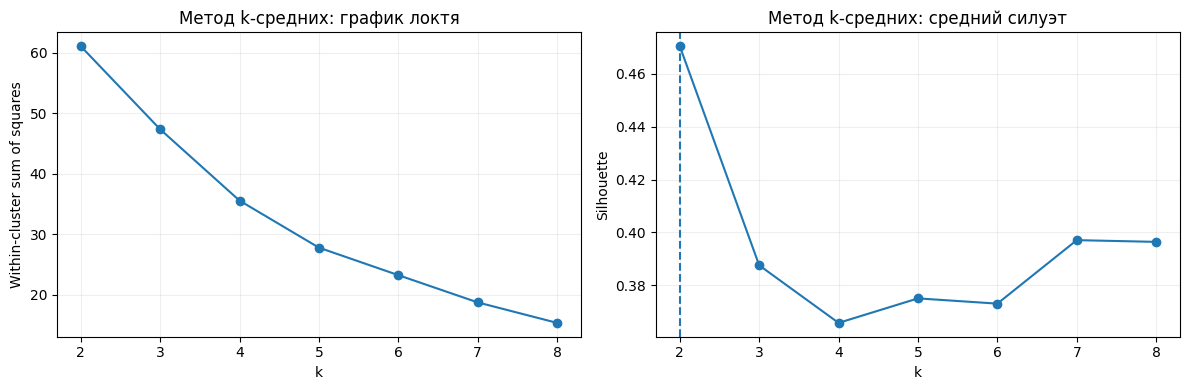

,Cities,Work,Price,Salary
KMeans,,,,
1,25,1789.24,84.97,59.03
2,21,1987.86,52.40,16.35


Кластер 1 (25 городов): Amsterdam, Brussels, Chicago, Copenhagen, Dublin, Dusseldorf, Frankfurt, Geneva, Helsinki, Houston, London, Los Angeles, Luxembourg, Madrid, Milan, Montreal, New York, Oslo, Paris, Stockholm, Sydney, Tokyo, Toronto, Vienna, Zurich
Кластер 2 (21 городов): Athens, Bogota, Bombay, Buenos Aires, Caracas, Hong Kong, Johannesburg, Kuala Lumpur, Lagos, Lisbon, Manila, Mexico City, Nairobi, Nicosia, Panama, Rio de Janeiro, San Paulo, Seoul, Singpore, Taipei, Tel Aviv


,City,Work,Price,Salary,KMeans
0,Amsterdam,1714.0,65.6,49.0,1
1,Brussels,1708.0,73.8,50.5,1
2,Chicago,1924.0,73.9,61.9,1
3,Copenhagen,1717.0,91.3,62.9,1
4,Dublin,1759.0,76.0,41.4,1
5,Dusseldorf,1693.0,78.5,60.2,1
6,Frankfurt,1650.0,74.5,60.4,1
7,Geneva,1880.0,95.9,90.3,1
8,Helsinki,1667.0,113.6,66.6,1
9,Houston,1978.0,71.9,46.3,1


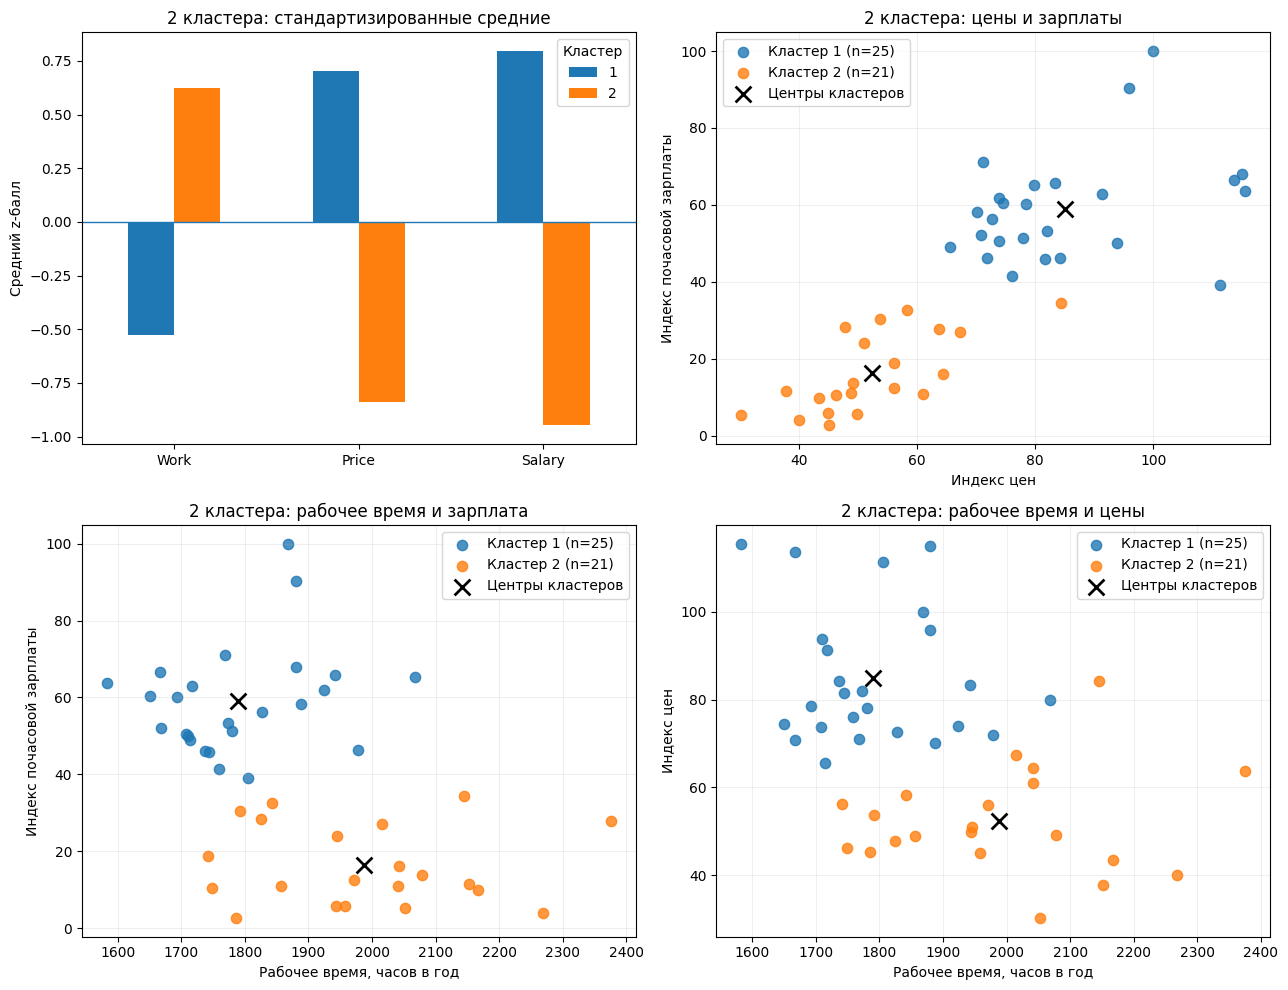

In [ ]:
# Сопоставляем графики инерции и силуэта, затем показываем размеры, состав и профили групп.
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(km_scores.k, km_scores.inertia, 'o-')
axes[0].set(title='Метод k-средних: график локтя', xlabel='k', ylabel='Within-cluster sum of squares', xticks=km_scores.k)
axes[1].plot(km_scores.k, km_scores.silhouette, 'o-')
axes[1].axvline(km_k, linestyle='--')
axes[1].set(title='Метод k-средних: средний силуэт', xlabel='k', ylabel='Silhouette', xticks=km_scores.k)
for ax in axes: ax.grid(alpha=.2)
plt.tight_layout(); plt.show()
km_summary = cities2.groupby('KMeans').agg(Cities=('City','size'), Work=('Work','mean'), Price=('Price','mean'), Salary=('Salary','mean'))
display(km_summary.round(2))
for c, part in cities2.groupby('KMeans'):
    print(f'Кластер {c} ({len(part)} городов):', ', '.join(part.City.str.replace('_', ' ').sort_values()))
display(cities2.sort_values(['KMeans','City']).reset_index(drop=True))

# Все три парные проекции используют одно разбиение по трём признакам.
def plot_kmeans_groups(model, group_labels, k):
    plot_data = cities2.assign(KMeans=group_labels)
    profiles = (pd.DataFrame(X2, columns=features2)
                .assign(KMeans=group_labels).groupby('KMeans').mean())
    # Возвращаем центры модели из стандартизированных в исходные единицы.
    centers = pd.DataFrame(scaler2.inverse_transform(model.cluster_centers_), columns=features2)
    fig, axes = plt.subplots(2, 2, figsize=(13, 10))
    axes = axes.ravel()
    profiles.T.plot.bar(ax=axes[0], rot=0)
    axes[0].axhline(0, linewidth=1)
    axes[0].set(title=f'{k} кластера: стандартизированные средние', ylabel='Средний z-балл')
    axes[0].legend(title='Кластер')
    for ax, x, y, title in [
        (axes[1], 'Price', 'Salary', 'Цены и зарплаты'),
        (axes[2], 'Work', 'Salary', 'Рабочее время и зарплата'),
        (axes[3], 'Work', 'Price', 'Рабочее время и цены')
    ]:
        for cluster, part in plot_data.groupby('KMeans'):
            ax.scatter(part[x], part[y], s=55, alpha=.8,
                       label=f'Кластер {cluster} (n={len(part)})')
        ax.scatter(centers[x], centers[y], marker='x', c='black',
                   s=130, linewidths=2, zorder=5, label='Центры кластеров')
        axis_names = {'Work': 'Рабочее время, часов в год',
                      'Price': 'Индекс цен', 'Salary': 'Индекс почасовой зарплаты'}
        ax.set(title=f'{k} кластера: {title.lower()}', xlabel=axis_names[x], ylabel=axis_names[y])
        ax.legend()
        ax.grid(alpha=.2)
    plt.tight_layout()
    plt.show()

plot_kmeans_groups(km_model, km_labels, km_k)


### Интерпретация, проверка и вывод

Выбран **k = 2**: средний силуэт **0,4705**. Кластеры содержат **25 и 21 город** и полностью совпадают с двухкластерным решением Ward из первой работы. Номера переупорядочены по средней зарплате для удобства сравнения.

| Группа | n | Work, среднее | Price, среднее | Salary, среднее | Смысл |
|---|---:|---:|---:|---:|---|
| 1 | 25 | 1789,24 | 84,97 | 59,03 | Более высокие цены и зарплаты, меньшее рабочее время |
| 2 | 21 | 1987,86 | 52,40 | 16,35 | Более низкие цены и зарплаты, большее рабочее время |


In [ ]:
# Сравниваем k-means с Ward на тех же стандартизированных наблюдениях.
ward2 = cut_tree(linkage(X2, method='ward'), n_clusters=2).ravel()
print('ARI k-means vs Ward:', adjusted_rand_score(km_labels, ward2))
# Проверяем выбранное k при 30 random_state и n_init=50.
# Это проверка зависимости от инициализации, а не от изменения данных.
km_repeats = []
for seed in range(30):
    repeat = KMeans(n_clusters=km_k, n_init=50, random_state=seed).fit(X2)
    km_repeats.append({'seed':seed, 'ARI':adjusted_rand_score(km_labels,repeat.labels_),
                       'inertia':repeat.inertia_})
km_repeats = pd.DataFrame(km_repeats)
display(km_repeats[['ARI','inertia']].agg(['min','median','max']).round(4))
cities2.to_csv('lab2_kmeans_clusters.csv', index=False, encoding='utf-8-sig')
km_summary.to_csv('lab2_kmeans_profiles.csv', encoding='utf-8-sig')
km_scores.to_csv('lab2_kmeans_scores.csv', index=False, encoding='utf-8-sig')


ARI k-means vs Ward: 1.0


,ARI,inertia
min,1.0,61.1166
median,1.0,61.1166
max,1.0,61.1166


## Что если взять другое количество кластеров?

Сравним разбиения k-means на 3 и 4 кластера с исходными двумя группами.


3 кластера: силуэт = 0.3875


,Cities,Work,Price,Salary
KMeans,,,,
1,25,1789.24,84.97,59.03
2,11,1855.45,50.78,16.59
3,10,2133.50,54.17,16.08


Кластер 1: Amsterdam, Brussels, Chicago, Copenhagen, Dublin, Dusseldorf, Frankfurt, Geneva, Helsinki, Houston, London, Los Angeles, Luxembourg, Madrid, Milan, Montreal, New York, Oslo, Paris, Stockholm, Sydney, Tokyo, Toronto, Vienna, Zurich
Кластер 2: Athens, Buenos Aires, Johannesburg, Lagos, Lisbon, Mexico City, Nairobi, Nicosia, Rio de Janeiro, San Paulo, Seoul
Кластер 3: Bogota, Bombay, Caracas, Hong Kong, Kuala Lumpur, Manila, Panama, Singpore, Taipei, Tel Aviv


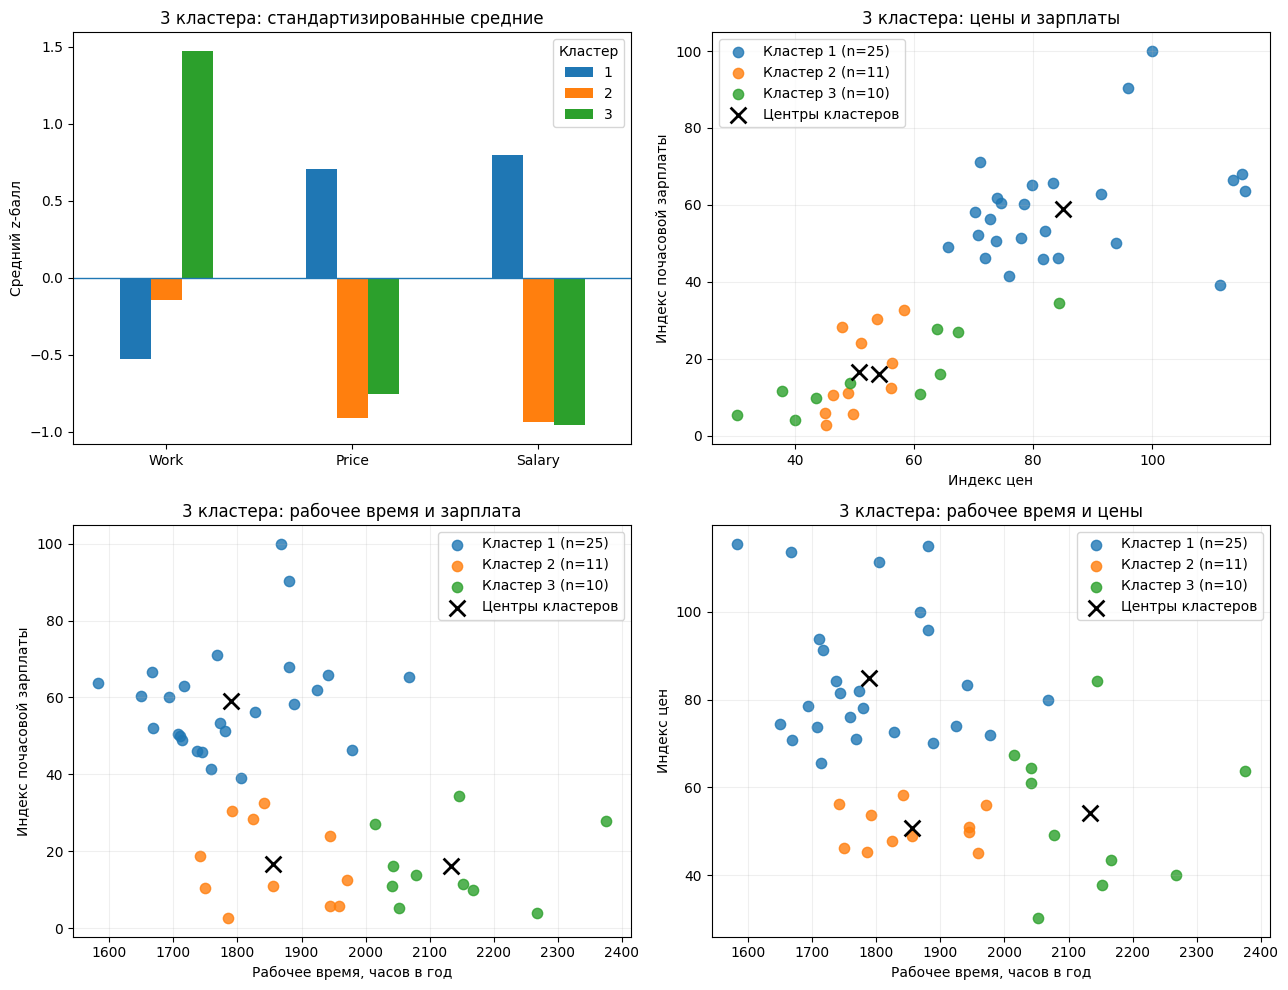

4 кластера: силуэт = 0.3658


,Cities,Work,Price,Salary
KMeans,,,,
1,6,1780.50,108.55,71.30
2,19,1792.00,77.53,55.16
3,11,1855.45,50.78,16.59
4,10,2133.50,54.17,16.08


Кластер 1: Geneva, Helsinki, Oslo, Stockholm, Tokyo, Zurich
Кластер 2: Amsterdam, Brussels, Chicago, Copenhagen, Dublin, Dusseldorf, Frankfurt, Houston, London, Los Angeles, Luxembourg, Madrid, Milan, Montreal, New York, Paris, Sydney, Toronto, Vienna
Кластер 3: Athens, Buenos Aires, Johannesburg, Lagos, Lisbon, Mexico City, Nairobi, Nicosia, Rio de Janeiro, San Paulo, Seoul
Кластер 4: Bogota, Bombay, Caracas, Hong Kong, Kuala Lumpur, Manila, Panama, Singpore, Taipei, Tel Aviv


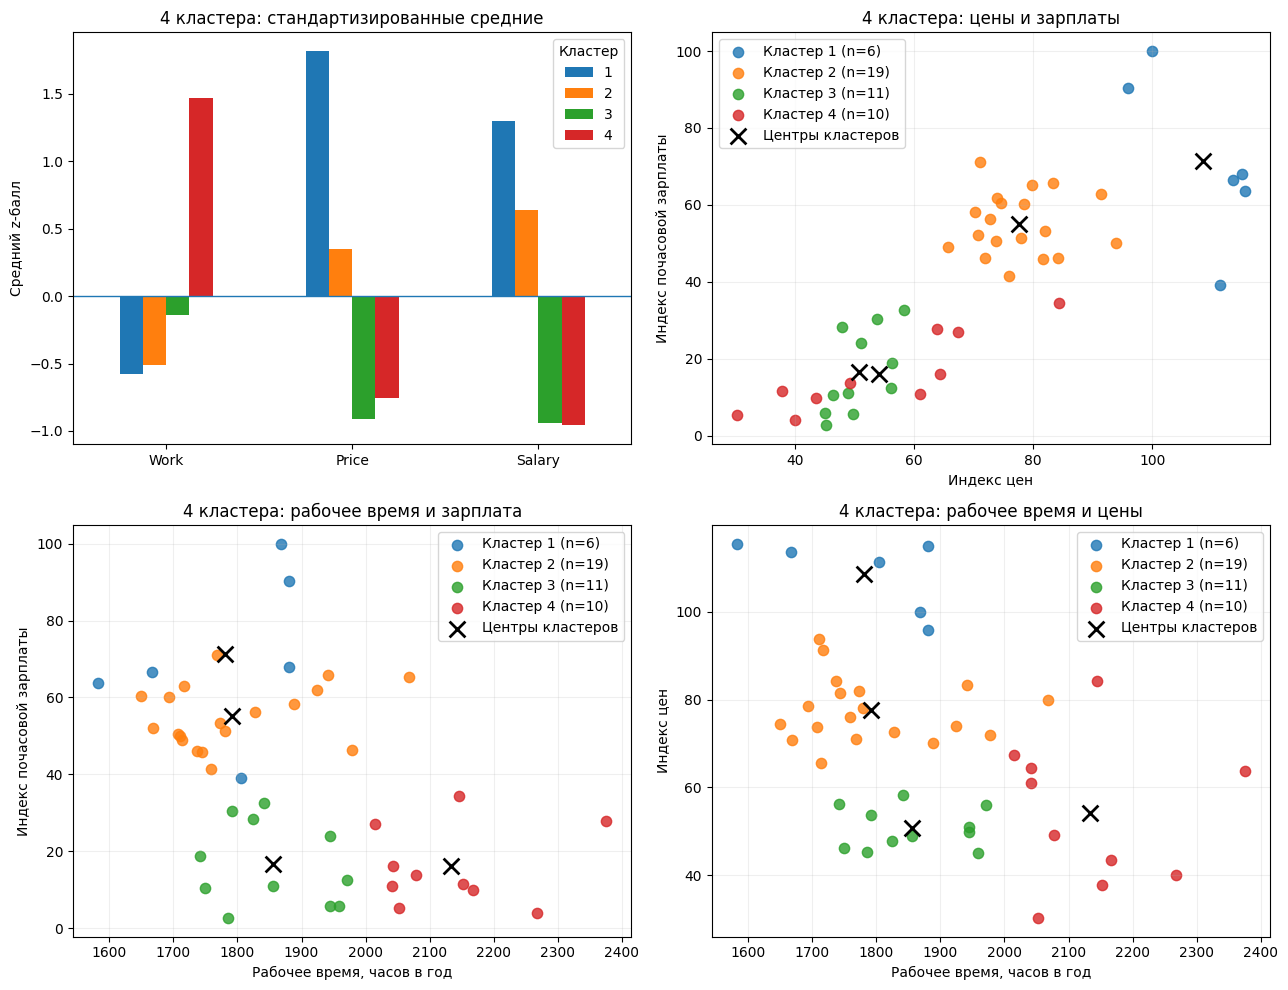

In [ ]:
# Для сравнения берём модели с теми же настройками и другим числом групп.
for k in [3, 4]:
    alternative_model2 = km_models[k]
    order = np.argsort(scaler2.inverse_transform(alternative_model2.cluster_centers_)[:, 2])[::-1]
    label_map = {int(old): new + 1 for new, old in enumerate(order)}
    alternative_labels2 = np.array([label_map[int(c)] for c in alternative_model2.labels_])
    alternative_cities2 = cities2.assign(KMeans=alternative_labels2)
    print(f'{k} кластера: силуэт = {silhouette_score(X2, alternative_labels2):.4f}')
    display(alternative_cities2.groupby('KMeans').agg(
        Cities=('City', 'size'), Work=('Work', 'mean'),
        Price=('Price', 'mean'), Salary=('Salary', 'mean')).round(2))
    for cluster, part in alternative_cities2.groupby('KMeans'):
        print(f'Кластер {cluster}:', ', '.join(part.City.str.replace('_', ' ').sort_values()))
    plot_kmeans_groups(alternative_model2, alternative_labels2, k)


### Интерпретация кластеров

**При разбиении на 3 кластера:**

**Кластер 1 — 25 городов.** Например, Лондон, Нью-Йорк, Токио. Та же группа с более высокими ЗП и ценами при меньшем количестве рабочих часов в год.

**Кластер 2 — 11 городов.** Например, Афины, Мехико, Сеул. ЗП и цены ниже, работают в среднем около 1855 часов в год.

**Кластер 3 — 10 городов.** Например, Бомбей, Гонконг, Сингапур. ЗП и цены примерно как во втором кластере, а работают заметно больше — около 2134 часов в год.

**При разбиении на 4 кластера:**

**Кластер 1 — 6 городов.** Например, Цюрих, Женева, Токио. Самые высокие средние цены и почасовая оплата, без увеличенного количества рабочих часов.

**Кластер 2 — 19 городов.** Например, Лондон, Нью-Йорк, Париж. ЗП и цены выше, чем в третьем и четвёртом кластерах, но ниже, чем в первом. Рабочее время примерно как в первом кластере.

**Кластер 3 — 11 городов.** Например, Афины, Мехико, Сеул. Та же группа с более низкими ЗП и ценами и меньшим рабочим временем, чем в четвёртом кластере.

**Кластер 4 — 10 городов.** Например, Бомбей, Гонконг, Сингапур. ЗП и цены близки к третьему кластеру, но работают заметно больше.

Разделение на 3–4 группы менее чёткое: две группы с низкими ЗП почти не отличаются по ценам и зарплатам и разделяются в основном по рабочему времени. Силуэт снижается с 0,4705 до 0,3875 и 0,3658. Номера кластеров здесь упорядочены по средней зарплате, поэтому при смене k номера похожих групп могут меняться.


### Сравнение чувствительности


,k,Силуэт,ARI с Ward,Минимальный ARI при смене seed,ARI после заполнения,Минимальный ARI при исключении,Медианный ARI при исключении,Полных совпадений из 46,Город с минимальным ARI
0,2,0.4705,1.0000,1.0,1.0,1.0000,1.0,46,Нет изменений
1,3,0.3875,0.8622,1.0,1.0,0.4023,1.0,44,Rio_de_Janeiro
2,4,0.3658,0.8378,1.0,1.0,0.7200,1.0,32,Hong_Kong


Пять наиболее заметных изменений для каждого числа кластеров:


,k,Excluded_city,ARI
0,2,Amsterdam,1.0000
1,2,Athens,1.0000
2,2,Bogota,1.0000
3,2,Bombay,1.0000
4,2,Brussels,1.0000
80,3,Rio_de_Janeiro,0.4023
60,3,Hong_Kong,0.8652
46,3,Amsterdam,1.0000
47,3,Athens,1.0000
48,3,Bogota,1.0000


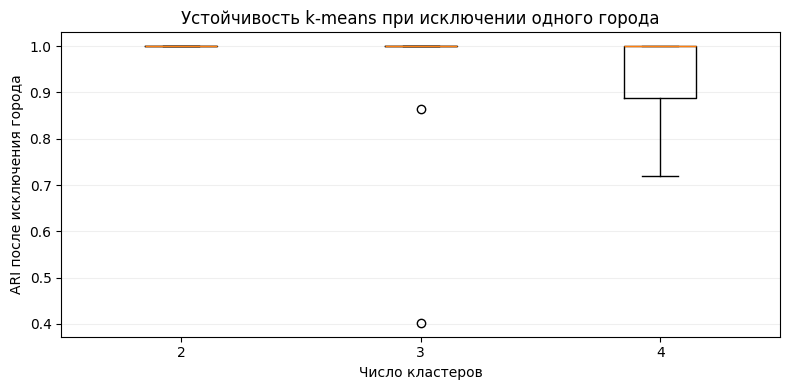

In [8]:
# Проверяем отдельно зависимость от инициализации и от изменения данных.
filled2 = raw2.copy()
filled2[features2] = filled2[features2].fillna(filled2[features2].median())
X_filled2 = StandardScaler().fit_transform(filled2[features2])
comparison_rows2, loo_rows2, seed_rows2 = [], [], []
for k in [2, 3, 4]:
    baseline = km_models[k].labels_
    ward_labels = cut_tree(linkage(X2, method='ward'), n_clusters=k).ravel()
    for seed in range(30):
        repeat = KMeans(n_clusters=k, n_init=50, random_state=seed).fit(X2)
        seed_rows2.append({'k': k, 'seed': seed,
                           'ARI': adjusted_rand_score(baseline, repeat.labels_)})

    # При заполнении пропусков сравниваем назначения исходных 46 полных городов.
    imputed_model = KMeans(n_clusters=k, n_init=50, random_state=42).fit(X_filled2)
    imputed = filled2[['City']].assign(Imputed=imputed_model.labels_)
    common = cities2[['City']].assign(Baseline=baseline).merge(imputed, on='City', validate='one_to_one')
    imputation_ari = adjusted_rand_score(common.Baseline, common.Imputed)

    current_loo = []
    for i in range(len(cities2)):
        mask = np.arange(len(cities2)) != i
        Xi = StandardScaler().fit_transform(cities2.loc[mask, features2])
        repeat = KMeans(n_clusters=k, n_init=50, random_state=42).fit(Xi)
        ari = adjusted_rand_score(baseline[mask], repeat.labels_)
        current_loo.append(ari)
        loo_rows2.append({'k': k, 'Excluded_city': cities2.loc[i, 'City'], 'ARI': ari})
    current_loo = np.array(current_loo)
    seed_ari = [row['ARI'] for row in seed_rows2 if row['k'] == k]
    comparison_rows2.append({
        'k': k, 'Силуэт': silhouette_score(X2, baseline),
        'ARI с Ward': adjusted_rand_score(baseline, ward_labels),
        'Минимальный ARI при смене seed': min(seed_ari),
        'ARI после заполнения': imputation_ari,
        'Минимальный ARI при исключении': current_loo.min(),
        'Медианный ARI при исключении': np.median(current_loo),
        'Полных совпадений из 46': np.isclose(current_loo, 1).sum(),
        'Город с минимальным ARI': ('Нет изменений' if np.isclose(current_loo, 1).all()
                                  else cities2.loc[current_loo.argmin(), 'City'])})

comparison2 = pd.DataFrame(comparison_rows2)
loo2 = pd.DataFrame(loo_rows2)
seeds2 = pd.DataFrame(seed_rows2)
display(comparison2.round(4))
print('Пять наиболее заметных изменений для каждого числа кластеров:')
display(loo2.sort_values(['k', 'ARI', 'Excluded_city']).groupby('k').head(5).round(4))
fig, ax = plt.subplots(figsize=(8, 4))
ax.boxplot([loo2.loc[loo2.k.eq(k), 'ARI'] for k in [2, 3, 4]])
ax.set(xticks=[1, 2, 3], xticklabels=['2', '3', '4'],
       xlabel='Число кластеров', ylabel='ARI после исключения города',
       title='Устойчивость k-means при исключении одного города')
ax.grid(axis='y', alpha=.2)
plt.tight_layout()
plt.show()
comparison2.to_csv('lab2_sensitivity_summary.csv', index=False, encoding='utf-8-sig')
loo2.to_csv('lab2_sensitivity_leave_one_out.csv', index=False, encoding='utf-8-sig')
seeds2.to_csv('lab2_sensitivity_seeds.csv', index=False, encoding='utf-8-sig')


### Результаты сравнения

При смене случайного начального состояния все 30 запусков с n_init=50 дают те же разбиения: ARI = 1 для 2, 3 и 4 групп. Медианное заполнение пропусков тоже не меняет назначения исходных 46 городов.

При исключении одного города разбиение на **2 кластера сохраняется во всех 46 проверках**. Для **3 кластеров — в 44 из 46**: удаление Рио-де-Жанейро сильно меняет результат, ARI падает до **0,4023**. Для **4 кластеров — в 32 из 46**, минимальный ARI **0,7200** при удалении Гонконга. Медианный ARI во всех случаях равен 1.

По сравнению с Ward разбиения на 3 и 4 группы уже различаются: ARI равен 0,8622 и 0,8378. Две группы совпадают полностью.

**Разбиение на 3–4 кластера менее чёткое и более чувствительное к отдельным городам.** При трёх группах изменения редкие, но иногда сильные; при четырёх происходят чаще. Более низкий силуэт и эти проверки поддерживают выбор двух групп. Проверенные случайные инициализации при 50 попытках сами по себе не добавляют нестабильности.
